# MiniMax versus GLM-5: coding outcomes and inference economics
## 0. Project overview
**Question: What does it cost to produce an accepted LangChain maintenance patch?**

Follow one coding attempt from issue to evaluation, see what we learned during development, then compare MiniMax M2.5 and GLM-5 on held-out tasks.

**Study workflow:** prepare tasks → tune the workflow on development tasks → freeze settings → run held-out tasks → compare outcomes and costs.

**One attempt:** load pre-fix source → reproduce the problem → inspect code → add a regression test → edit source → run checks → capture the workspace → evaluate independently → record the result and cost. The agent may repeat inspection, editing and checks within its budget.

An accepted patch passes every required check under that attempt's frozen policy. Acceptance means ** automated checks passed, human review awaits**. It does not authorize merging. In the later workflow, the final workspace is evaluated even when the agent stops at a budget limit; explicit submission is recorded separately.

| Component | Role |
| --- | --- |
| Harbor | Runs jobs and collects results and artifacts |
| mini-SWE-agent | Runs the coding loop |
| OpenRouter | Routes model requests and reports usage and cost |
| MiniMax M2.5 and GLM-5 | AI Models that generate actions; pinned endpoints and precision appear below |
| Docker | Isolates commands and task dependencies |
| Project code | Enforces study-specific budgets and policies, reconciles charges and presents results |

Both selected model endpoints advertise FP8 precision. Results describe these model/provider configurations under the frozen workflow; they do not isolate precision or provider effects.

**Run this notebook:** install `notebooks/requirements.txt` and open it from the full project root. **Replay** reads saved results without network access, Docker or paid inference. **Execute** additionally requires the prepared task images, validated public task resources and host-side credentials. Replay reproduces the analysis; it does not rerun the agent or rebuild task environments.

The notebook shows the selected run's first exchange. The original first-execution display is preserved below. Numeric evidence is included locally. Raw traces and candidate patches are excluded from public files.

**Public preparation:** `python -m experiments.portable_prepare doctor` reports readiness for all 13 tasks. Run `prepare TASK_ID --allow-setup-network --controls` to reconstruct pinned resources and validate them with zero inference. Public protocol IDs are distinct from historical acceptance. The walkthrough explains the saved annotated-tools attempt; Execute can launch any selected ready task and labels its actual task and protocol before inspecting its first exchange.


In [2]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import HTML, SVG, display
from experiments import notebook_workflow as workflow
from experiments import notebook_presentation as presentation
from experiments.tutorial import source_text, patch_html
from public_replay.analysis import comparison, measured_attempts

ROOT = Path.cwd().resolve()
if not (ROOT / "configs/study.json").is_file():
    raise RuntimeError("Open main.ipynb from this repository root")
MODE = "replay"
CONFIRM_PAID_EXECUTION = False
EXECUTE_TASK_ID = "LC-INT-TEMPERATURE-001"  # Any task with passing public controls.
EXECUTE_MODEL = "minimax"  # Or "glm5"; both use pinned providers.
FRESH_ATTEMPT_ID = None  # Execute requires a new unique ID; existing IDs are rejected.
STUDY_ID = workflow.DEMO_STUDY
SAVED_RUN_ID = workflow.DEMO_RUN_ID
by_id = {r["run_id"]: r for r in workflow.records(ROOT)}
view = json.loads((ROOT / "notebooks/tutorial-study.json").read_text())
bundle = workflow.public_evidence(ROOT)
study = bundle.read("study.json")
print("Mode:", MODE.title())
display(presentation.stack_models(study))
display(HTML(presentation.details(ROOT, "Selected saved run identity", {"run_id": SAVED_RUN_ID})))
# Local readiness is separate from the historical outcome tables.
from experiments.portable_prepare import doctor
public_readiness = doctor(ROOT)
display(pd.DataFrame([{ "Task": task, "Protocol": item["protocol_id"], "Ready locally": item["execute_ready"] } for task, item in public_readiness["tasks"].items()]))


Mode: Replay


,Model,Pinned provider,Precision
0,MiniMax M2.5,minimax/fp8,advertised precision: FP8
1,GLM-5,z-ai/fp8,advertised precision: FP8


,Task,Protocol,Ready locally
0,LC-ASYNC-TOOLS-001,public-lc-async-tools-001-v1,False
1,LC-SUMMARY-OVERFLOW-001,public-lc-summary-overflow-001-v1,False
2,LC-FIREWORKS-RERANK-001,public-lc-fireworks-rerank-001-v1,False
3,LC-OPENROUTER-PROVIDER-001,public-lc-openrouter-provider-001-v1,False
4,LC-HF-ACCELERATOR-001,public-lc-hf-accelerator-001-v1,False
5,LC-JSON-INPUT-001,public-lc-json-input-001-v1,False
6,LC-INT-TEMPERATURE-001,public-lc-int-temperature-001-v1,False
7,LC-PARALLEL-TOOL-MERGE-001,public-lc-parallel-tool-merge-001-v1,False
8,LC-ANNOTATED-TOOLS-001,public-lc-annotated-tools-001-v1,False
9,LC-CHROMA-NONE-001,public-lc-chroma-none-001-v1,False


## 1. One task end to end
### 1.1 The issue: missing tool-parameter descriptions
**[LangChain issue #31051](https://github.com/langchain-ai/langchain/issues/31051): tool descriptions are lost when Python stores annotations as strings.**

With `from __future__ import annotations`, `@tool` kept the parameter type but lost the description inside `Annotated`. The fix must preserve the description, types and tool invocation.

Readers can inspect [fixing PR #31181](https://github.com/langchain-ai/langchain/pull/31181). The evaluated agent never receives this reference.

Minimal example for the prepared task environment:

```python
from __future__ import annotations
from typing import Annotated
from langchain_core.tools import tool

@tool
def choose_fragments(parts: Annotated[list[str], "Fragments to evaluate"]) -> list[str]:
    """Return the requested fragments."""
    return parts

print(choose_fragments.args["parts"])
```

**Expected:** the schema includes `Fragments to evaluate`. **Before the fix:** that description is missing. The next cell compares recorded baseline output with the expected result.

In [3]:
prepared = workflow.preparation(ROOT, STUDY_ID)
actual_expected, reproduction = presentation.issue_outputs(ROOT, prepared)
display(actual_expected)
print({k: v for k, v in reproduction.items() if k != "evidence"})
display(HTML(presentation.details(ROOT, "Source provenance, versions and evidence hashes", {
    "starting_commit": prepared["frozen"]["starting_commit"],
    "baseline_checksum": prepared["frozen"]["baseline_checksum"],
    "setting_id": prepared["frozen"]["setting_id"],
    "task_python": prepared["frozen"].get("task_python"),
    "reproduction_receipt": reproduction["evidence"]})))

{'recorded_exit_code': 1, 'observed_failure': 'AssertionError: Annotated parameter description missing'}


,Property,"Actual, unchanged code",Expected
0,description,missing,Fragments to evaluate
1,type,array,array
2,items.type,string,string


### 1.2 Check the setup before testing a model
Can the environment distinguish broken code from a valid fix?

Following a SWE-bench-style approach, trusted preparation checks that the pre-fix source fails and a reference fix passes. It also checks that a valid workspace is captured and accepted after a budget stop or execution error. These controls use **zero model calls**. Reference fixes and hidden tests remain outside the agent's environment.

This cell reads those saved controls. It does not build an environment. Execute requires the prepared resources and images; missing resources stop the launch before inference.

In [4]:
display(presentation.controls(prepared))
display(HTML(presentation.details(ROOT, "Full setup receipts and environment", {
    "controls": prepared["controls"], "environment": prepared["environment"]})))

,Setup check,Expected patch accepted,Observed patch accepted,Model calls,Status
0,Unchanged code → expected failure,False,False,0,matches expectation
1,Reference fix → expected pass,True,True,0,matches expectation
2,Valid workspace at budget stop → still accepted,True,True,0,matches expectation
3,Valid workspace at error stop → still accepted,True,True,0,matches expectation


### 1.3 Prepare Harbor and the coding agent
Harbor runs the job. mini-SWE-agent sends requests and executes the model's bash commands. Requests run through the host-side model client; commands run inside offline Docker. A separate trusted environment evaluates the final workspace.

This historical example allows **30 requests, 10,000 total output tokens, 20 minutes and 1,500 output tokens per response**. Section 3 shows the later comparison settings, which allow 6,000 tokens per response.

In [5]:
preview = workflow.request_preview(ROOT, prepared)
display(presentation.budget_table(prepared["policy"]["budgets"]))
print(presentation.relative_paths(ROOT, workflow.launch_command(ROOT, prepared)))
display(HTML(presentation.details(ROOT, "Actual Harbor configuration", prepared["job"])))
display(HTML(presentation.details(ROOT, "Production launcher — used by measured runs",
    source_text(ROOT, "experiments/launch.py", "launch"))))
display(HTML(presentation.details(ROOT, "Production model request construction and invocation",
    source_text(ROOT, "agent/mini_runtime.py", "MeteredModel.query"))))

.venv/bin/harbor run -c configs/harbor-workspace-deliverable-v2-model.json --env-file '<host-only credentials file>' --job-name YOUR_UNIQUE_FRESH_ATTEMPT_ID


,Wall-clock limit (seconds),Model request limit,Cumulative output token limit,Tool-format repair limit,Command limit (seconds),Per-response output token limit
0,1200,30,10000,2,90,1500


### 1.4 Build the model request
The first request contains **system instructions, the task and the remaining budget**, plus the bash tool definition. Instructions and allowed paths are fixed. Later requests add the agent's actions, tool results and updated budget messages.

`provider.only` selects the serving endpoint. Fallback is disabled. `max_tokens` limits each response within the remaining total output budget. Sampling temperature is a separate model setting.

The display uses repository-relative paths for readability; historical saved evidence retains its values; private host paths are relocated.
Replay shows a clearly labelled historical request summary. Exact prompt wording is privately preserved; fresh Execute renders the actual request locally.


In [6]:
display(presentation.model_settings(preview))
display(HTML(presentation.messages_html(ROOT, preview["messages"])))
display(pd.DataFrame([{"Tool": "bash", "Input": "command: string", "Access": "offline sandbox only"}]))
display(HTML(presentation.details(ROOT, "Historical request summary and recorded controls", preview)))

,Model,Pinned provider,Fallbacks,Sampling temperature,Reasoning,Output ceiling
0,minimax/minimax-m2.5,minimax/fp8,False,0,parameter omitted,1500


,Tool,Input,Access
0,bash,command: string,offline sandbox only


### 1.5 Replay a saved attempt or launch a fresh one
**Replay** loads `SAVED_RUN_ID`. **Execute** checks preparation, then launches Harbor with fresh source, containers and agent context.

To execute, set `MODE="execute"`, enable confirmation and provide a new `FRESH_ATTEMPT_ID`. Existing IDs are rejected. Replay displays an author-written summary of the historical first request and the retained first response. Execute displays the actual fresh request and response locally.

In [7]:
if MODE == "execute":
    if CONFIRM_PAID_EXECUTION is not True:
        raise ValueError("Paid Harbor execution requires explicit confirmation")
    if FRESH_ATTEMPT_ID is None:
        raise ValueError("Choose a new explicit FRESH_ATTEMPT_ID before Execute")
if MODE == "execute":
    result = workflow.execute_public(ROOT, task_id=EXECUTE_TASK_ID, model=EXECUTE_MODEL,
        confirmed=CONFIRM_PAID_EXECUTION, job_name=FRESH_ATTEMPT_ID)
    fresh_prepared = workflow.public_preparation(ROOT, EXECUTE_TASK_ID)
    preview = workflow.request_preview(ROOT, fresh_prepared)
    print({"Fresh task": EXECUTE_TASK_ID, "Public protocol": result["public_protocol"]})
else:
    result = workflow.execute_or_replay(ROOT, mode=MODE, saved_run_id=SAVED_RUN_ID,
        study_id=STUDY_ID)
run = result["record"]
print({"Mode": result["mode"], "Fresh run launched": result["launched"], "Original classification": run["classification"].replace("_", " ")})
display(HTML(presentation.details(ROOT, "Selected attempt identity", {"run_id": run["run_id"]})))

{'Mode': 'replay', 'Fresh run launched': False, 'Original classification': 'checks passed pending review'}


In [8]:
exchange = workflow.first_exchange(run)
actual_first = exchange["request"]
print({"selected_run": run["run_id"], "first_request_status": exchange["status"],
       "response_status": exchange["response_status"],
       "prepared_request_matches_actual": "historical request summarized; exact comparison omitted" if exchange.get("summarized") else (preview == actual_first if actual_first else "not run")})
rendered_first = presentation.exchange_html(ROOT, run)
display(HTML(rendered_first))
print(presentation.preserve_invocation(ROOT, run, rendered_first, MODE))

{'selected_run': 'annotated-tools-workspace-v2-minimax-attempt-001/LC-ANNOTATED-TOOLS-001__4SxgJND', 'first_request_status': 'historical request summarized; original first response and numeric usage retained', 'response_status': 'recorded', 'prepared_request_matches_actual': 'historical request summarized; exact comparison omitted'}
Replay: original native trace and historical notebook archives retained; no new file written.


In [9]:
# Read the same saved request with decoded line breaks and expandable fields.
# Historical requests are summarized; fresh Execute displays the actual local request.
from experiments.notebook_json import readable_json
selected_request = workflow.first_exchange(run)["request"]
display(HTML(readable_json(presentation.relative_paths(ROOT, selected_request))))

**How context grows:** request 2 includes the first agent action, the reproducer's output and an updated budget message. The next cell compares recorded numeric context counts and summarizes what was added. Input-token counts describe each request, not cumulative usage or persistent memory. Cached tokens still count toward the input context.

In [10]:
context_requests, added_messages, context_receipt = presentation.context_demo(run, bundle)
display(context_requests)
print(context_receipt["status"])
display(HTML(presentation.messages_html(ROOT, added_messages)))
display(HTML(presentation.details(ROOT, "Recorded context counts and author-written message summaries", context_receipt)))
milestones = presentation.milestone_actions(run)
if milestones.empty:
    print("No sandbox actions recorded")
else:
    display(milestones.rename(columns={"request": "Request number", "command": "Recorded action (author summary)",
        "exit": "Exit code", "observation (tail)": "Recorded result (author summary)"}))
# Heredoc payloads are excluded when identifying actual test/check executions.

saved request comparison


,Request number,Message count,Provider-reported input tokens,Estimated visible-payload tokens (estimate)
0,1,3,2923,unknown
1,2,5,3118,unknown


,Milestone,Request number,Recorded action (author summary),Exit code,Recorded result (author summary)
0,reproduction,1,Ran the unchanged-source reproducer; parameter...,1,Recorded command exit: 1. Numeric check result...
1,source edit,11,Edited annotation resolution in tool-schema ha...,0,Recorded command exit: 0. Numeric check result...
2,test creation,13,Added a regression file covering tool paramete...,0,Recorded command exit: 0. Numeric check result...
3,verification execution,14,Executed the candidate regression tests throug...,0,Recorded command exit: 0. Numeric check result...
4,"submission, last observed action",21,Submitted the final workspace for independent ...,0,Recorded command exit: 0. Numeric check result...


### 1.6 Inspect the candidate behavior and evaluation
The controller captures the workspace when the agent submits, exhausts its budget or stops with an error. The trusted evaluator checks the candidate in a clean environment.

New regression tests must fail on the unchanged source and pass on the candidate. Existing tests, file policy, lint, formatting, typing and hidden acceptance checks must also pass. The table separates patch acceptance from explicit submission.

In [11]:
candidate = workflow.candidate_evidence(run)
if MODE == "execute":
    display(HTML(presentation.details(ROOT, "Actual fresh candidate patch (local artifact)", candidate.get("patch", "not recorded"))))
    display(HTML(presentation.details(ROOT, "Actual fresh evaluation checks (local artifacts)", candidate["checks"])))
display(HTML(presentation.details(ROOT, "Recorded candidate behavior", candidate.get("explanation", "Fresh final workspace captured and evaluated independently. Source-bearing artifacts remain in ignored run storage."))))
display(presentation.checks_frame(run, split="development"))
display(pd.DataFrame([{
    "Termination reason": str(run.get("termination_reason", "unknown")).replace("_", " "),
    "Explicit submission": run.get("explicit_submission"), "Patch accepted": run.get("patch_accepted"),
    "Task success": run.get("task_success"), "Original classification": str(run.get("classification", "unknown")).replace("_", " ")}]))
display(HTML(presentation.details(ROOT, "Recorded capture receipt", candidate["receipt"])))


,check,expected exit,observed exit,status
0,file_policy,0,0,pass
1,regression_on_baseline,1,1,pass
2,reproducer,0,0,pass
3,regression,0,0,pass
4,existing_tests,0,0,pass
5,lint,0,0,pass
6,format,0,0,pass
7,types,0,0,pass
8,hidden_acceptance,0,0,pass


,Termination reason,Explicit submission,Patch accepted,Task success,Original classification
0,submitted,True,True,True,checks passed pending review


### 1.7 Calculate this attempt's inference cost
Add the charges for every model request, including failed or malformed responses. Use OpenRouter's reported usage and cost, reconciled with saved Generation API receipts where available. Missing charges remain unknown. Reported reasoning and cached-input tokens are already included in their respective totals; do not add them twice.

Harbor supplies the run artifacts. Project code reconciles request charges and calculates cost per accepted patch: **total inference spend ÷ accepted patches**, including unsuccessful attempts in the spend.

In [12]:
ledger, attempt_economics = workflow.accounting(ROOT, run)
usage_columns = ["request_number", "input_tokens", "output_tokens", "effective_cost_usd", "tool_format_error"]
if ledger.empty:
    print("No request usage recorded; consult completeness status below")
else:
    short_usage = pd.concat([ledger.head(3), ledger.tail(2)]).drop_duplicates("request_number")
    display(short_usage[usage_columns].rename(columns={"request_number": "Request number", "input_tokens": "Reported input tokens", "output_tokens": "Reported output tokens", "effective_cost_usd": "Reconciled charge (USD)", "tool_format_error": "Tool-format error"}))
display(pd.DataFrame([{k: v for k, v in attempt_economics.items() if k != "usage"}]))
display(HTML(presentation.details(ROOT, "Every request and sum inputs, including failures", ledger.to_dict("records"))))
display(HTML(presentation.details(ROOT, "Native reasoning/cache usage and completeness", attempt_economics["usage"])))

,Request number,Reported input tokens,Reported output tokens,Reconciled charge (USD),Tool-format error
0,1,2923,109,0.001008,None
1,2,3118,166,0.000395,None
2,3,3301,66,0.000280,None
19,20,16659,98,0.000809,None
20,21,17230,208,0.001083,None


,requests including failures,known reported spend USD,complete reported spend USD,cost complete,accepted patch,explicit submission,cost per accepted patch USD
0,21,0.021484,0.021484,True,True,True,0.021484


## 2. Development tasks and lessons
Development covered four bugs and one feature request. We changed instructions, response limits and environment setup as we diagnosed failures. These attempts span different configurations, so they are a learning history rather than a controlled model comparison.

**Task difficulty is author-assigned:**

- **L1:** a localized change with a clear requirement and limited interaction between components.
- **L2:** coordinated changes across execution paths, components or files, with more compatibility cases to preserve.

These presentation ratings describe expected task complexity, not model performance. They do not replace the original recorded metadata.

The roster covers all development tasks. The selected transitions show lessons from destructive edits and the earlier submission requirement. Original verdicts and costs remain unchanged.

In [13]:
development_roster, roster_audit = presentation.development_roster(ROOT, bundle)
display(HTML(presentation.roster_html(development_roster)))
display(HTML(presentation.details(ROOT, "Development roster metadata sources and exact records", roster_audit)))
development, development_audit = presentation.development_transitions(by_id, view)
display(HTML(presentation.transition_table_html(development)))
display(HTML(presentation.details(ROOT, "Original runs, configuration hashes and verdicts", development_audit)))

Issue / PR,Problem,Family,Outcome summary,Author-assigned difficulty
PR #31698,Initialize ChatOpenAI with custom timeouts without losing values or client reuse.,bug fix,MiniMax M2.5: 0/2 original successes; 0 patches accepted; 2 acceptance records unknown · GLM-5: not run,L2
PR #31756,Retain cached-input and reasoning-token usage details in Responses API results.,bug fix,MiniMax M2.5: 1/1 original successes; 1 patches accepted · GLM-5: not run,L1
PR #31181,Retain tool parameter descriptions when annotations are stored as strings.,bug fix,MiniMax M2.5: 1/3 original successes; 2 patches accepted · GLM-5: not run,L2
PR #31377,Skip missing Chroma document content without discarding valid documents.,bug fix,MiniMax M2.5: 0/2 original successes; 0 patches accepted · GLM-5: not run,L2
Issue #39757,Let callers supply the counter used to trigger and perform context editing.,feature request,MiniMax M2.5: 0/4 original successes; 0 patches accepted · GLM-5: 1/2 original successes; 1 patches accepted,L1


Problem,Change introduced,Next outcome,Learning
Large edits destroyed source structure,"Focused replacements, immediate diff checks and Git-free restore",MiniMax M2.5: accepted · submission protocol failure,"The next patch was accepted, but its original submission-based task verdict stayed unsuccessful."
A usable patch could be discarded for missing submission,Final workspace capture and evaluation; submission scored separately,MiniMax M2.5: accepted,"The next fresh attempt passed checks and submitted; this demonstrates an end-to-end path, not a causal estimate."


### Feature request: custom token counting
**[Issue #39757](https://github.com/langchain-ai/langchain/issues/39757): let callers supply a token counter to `ContextEditingMiddleware`.**

Approximate counting can under-count CJK-heavy conversations, and some providers cannot count tokens through their model API. The requested constructor is:

`ContextEditingMiddleware(..., token_counter: TokenCounter | None = None)`

The custom counter must control both the editing trigger and subsequent counting in synchronous and asynchronous wrappers. Without one, existing behavior must stay the same.

Six paid calibration attempts tested file-writing instructions, a larger response allowance and the repaired environment. Separate controls used no inference to validate the permitted test location and fix mypy's cache-write failure.

In [14]:
feature_changes, feature_audit = presentation.feature_transitions(by_id, view)
feature_activity, startup_receipts = presentation.feature_activity(ROOT, bundle)
print("Paid calibration attempts:", feature_activity["paid_attempts"], feature_activity["paid_attempts_by_model"])
print("Separate startup incidents:", feature_activity["startup_incidents_not_paid_attempts"],
      "with", feature_activity["startup_model_calls"], "model calls; not paid attempts")
display(HTML(presentation.details(ROOT, "Startup incident evidence, separate from calibration", startup_receipts)))
display(HTML(presentation.transition_table_html(feature_changes)))
repair = json.loads((ROOT / view["environment_repair_setting"]).read_text())
print({"recorded environment-repair setup calls": repair.get("setup_model_requests", "not recorded")})
display(HTML(presentation.details(ROOT, "Feature settings, hashes and original outcomes", feature_audit)))
display(HTML(presentation.details(ROOT, "Recorded zero-inference environment repair", repair)))

Paid calibration attempts: 6 {'MiniMax M2.5': 4, 'GLM-5': 2}
Separate startup incidents: 1 with 0 model calls; not paid attempts
{'recorded environment-repair setup calls': 0}


Problem,Change introduced,Next outcome,Learning
Custom-counter API and regression coverage needed,"Initial feature attempt: 1,500-token response allowance",MiniMax M2.5: not accepted · tool format recovery failure,Malformed test-writing calls left no new regression file; the candidate was rejected.
Large file-writing arguments were truncated,"Incremental edits; keep the 1,500-token response ceiling",MiniMax M2.5: not accepted · tool format recovery failure,The short-edit instruction alone did not resolve tool-format recovery in this attempt.
Tool arguments needed more room per response,"Larger response allowance: 6,000; total calls/tokens unchanged",MiniMax M2.5: not accepted · regression and lint failure,"Complete larger payloads became possible, but regression and lint failures still rejected the candidate."
Check behavior needed testing with the second model,GLM-5 calibration under the same effective limits,GLM-5: not accepted · file policy failure,An intermediate passing workspace did not qualify the final captured candidate; file policy and typing setup still needed repair.
Test-directory policy and mypy cache limit were inconsistent,Environment repair: validated test root and cacheless typing — MiniMax,MiniMax M2.5: not accepted · lint and format failure,"Functional checks passed, but remaining lint/format errors kept this fresh attempt unsuccessful."
Repeat calibration after zero-inference setup repair,Environment repair: same repaired setup — GLM-5,GLM-5: accepted,The fresh candidate passed every required check. Earlier failures and their costs remain unchanged.


## 3. Freeze the comparison settings
Both models receive the same effective instructions, tools, checks and budgets: **30 requests, 10,000 total output tokens, up to 6,000 per response and 20 minutes**. Each response is also limited by the remaining total allowance.

Provider endpoints and reasoning settings are fixed per model. Each task has its own validated pre-fix environment. Every attempt starts with fresh source and empty agent context; previous patches, trajectories and hidden-test feedback are not supplied.

In [15]:
display(presentation.budget_table(study["harness"]["budgets"]))
for model, settings in study["model_preparation"].items():
    display(presentation.model_settings(settings))
held_report = json.loads((ROOT / "reports/held-out-six-task-repeats/results.json").read_text())
display(HTML(presentation.details(ROOT, "Frozen setting, task environments and source provenance", {
    "six_task_setting_id": held_report["setting_id"], "harness": study["harness"], "tasks": bundle.read("tasks.json")})))

,Cumulative output token limit,Model request limit,Tool-format repair limit,Per-response output token limit,Wall-clock limit (seconds),Command limit (seconds)
0,10000,30,2,6000,1200,90


,Model,Pinned provider,Fallbacks,Sampling temperature,Reasoning,Output ceiling
0,minimax/minimax-m2.5,minimax/fp8,False,0.0,parameter omitted,6000


,Model,Pinned provider,Fallbacks,Sampling temperature,Reasoning,Output ceiling
0,z-ai/glm-5,z-ai/fp8,False,0.0,"{""enabled"": false}",6000


## 4. Held-out tasks and results
The first two tasks received **one attempt per model: 4 launches**. The remaining six received **three attempts per model: 36 launches**. That gives **40 recorded launches across eight tasks**.

The first two tasks and the six-task repeated comparison are reported separately. Only the six-task group has three attempts per model/task.

For that group, the chart divides all 18 launches per model into **accepted, unsuccessful and interrupted**. Acceptance percentages use all launches as the denominator. Interrupted runs remain visible and are not treated as completed coding-performance observations. Explicit submission is a separate measure.

Recorded held-out launches: 4 + 36 = 40


Issue / PR,Problem,Family,Author-assigned difficulty,MiniMax M2.5 results,GLM-5 results
Issue #40205,Support asynchronous tool declarations and preserve their metadata.,feature,L2,1 launches; 0 accepted; 0 interrupted,1 launches; 0 accepted; 0 interrupted
Issue #41155,Avoid identical overflow retries; recover using reduced input.,bug fix error handling,L2,1 launches; 0 accepted; 0 interrupted,1 launches; 0 accepted; 1 interrupted
Issue #39340,Add a Fireworks document reranker.,feature,L2,3 launches; 0 accepted; 1 interrupted,3 launches; 0 accepted; 1 interrupted
Issue #39298,Preserve the actual serving provider in response metadata.,feature,L1,3 launches; 0 accepted; 0 interrupted,3 launches; 0 accepted; 1 interrupted
Issue #38855,Support non-CUDA accelerator discovery for Hugging Face pipelines.,feature,L1,3 launches; 0 accepted; 0 interrupted,3 launches; 2 accepted; 0 interrupted
Issue #39192,Reject unsupported JSON-splitter input rather than silently discarding it.,bug fix,L1,3 launches; 0 accepted; 0 interrupted,3 launches; 3 accepted; 0 interrupted
Issue #35300,Keep integer temperature values in tracing metadata.,bug fix,L1,3 launches; 1 accepted; 0 interrupted,3 launches; 3 accepted; 0 interrupted
Issue #34807,Keep distinct parallel tool-call chunks from being merged together.,bug fix,L2,3 launches; 1 accepted; 0 interrupted,3 launches; 3 accepted; 0 interrupted


Task,Model,Attempt,Patch verdict,Explicit submission
Issue #40205 — Support asynchronous tool declarations and preserve their metadata.,GLM-5,1,not accepted,False
Issue #40205 — Support asynchronous tool declarations and preserve their metadata.,MiniMax M2.5,1,not accepted,False
Issue #41155 — Avoid identical overflow retries; recover using reduced input.,GLM-5,1,interrupted; original rejection retained,False
Issue #41155 — Avoid identical overflow retries; recover using reduced input.,MiniMax M2.5,1,not accepted,False


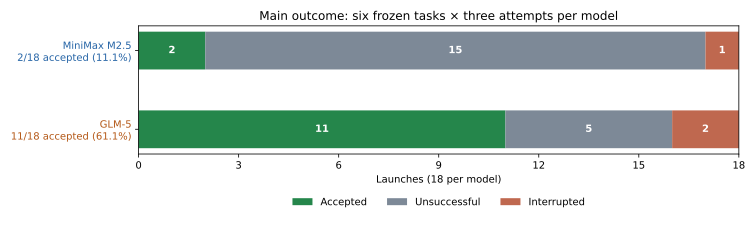

Task,MiniMax M2.5,GLM-5
Issue #39340 — Add a Fireworks document reranker.,0/3 · 1 interrupted,0/3 · 1 interrupted
Issue #38855 — Support non-CUDA accelerator discovery for Hugging Face pipelines.,0/3,2/3
Issue #35300 — Keep integer temperature values in tracing metadata.,1/3,3/3
Issue #39192 — Reject unsupported JSON-splitter input rather than silently discarding it.,0/3,3/3
Issue #39298 — Preserve the actual serving provider in response metadata.,0/3,0/3 · 1 interrupted
Issue #34807 — Keep distinct parallel tool-call chunks from being merged together.,1/3,3/3


,Model,Accepted / launched,Interruptions,Explicit submissions,Accepted launches (%)
0,MiniMax M2.5,2/18,1,4,11.1
1,GLM-5,11/18,2,15,61.1


In [16]:
heldout_roster, heldout_audit, heldout_counts = presentation.heldout_roster(ROOT, bundle)
display(HTML(presentation.roster_html(heldout_roster)))
print("Recorded held-out launches:", heldout_counts["held_out_two"], "+", heldout_counts["held_out_six"], "=", heldout_counts["held_out_total"])
display(HTML("<h4>First two tasks: one attempt per task/model — 4 launches</h4>"))
display(HTML(presentation.results_table_html(presentation.first_two_results(bundle))))
display(HTML(presentation.details(ROOT, "All eight task metadata receipts and run identities", heldout_audit)))
display(HTML("<h4>Six-task repeated comparison — 36 launches only</h4>"))
attempts = measured_attempts(bundle)
held = presentation.held_frame(bundle)
asset_root, plot_receipt = presentation.assets(ROOT)
display(SVG(filename=str(asset_root / "main-outcomes.svg")))
per_task_acceptance, overall_acceptance = presentation.acceptance_tables(bundle)
display(HTML(presentation.results_table_html(per_task_acceptance)))
display(overall_acceptance)
display(HTML(presentation.details(ROOT, "Run IDs and original outcomes, including interruptions",
    held[["run_id", "configuration_id", "classification", "patch_accepted", "explicit_submission", "infrastructure_interrupted"]].to_dict("records"))))

## 5. Inference economics and resource use
### Cost per accepted patch
**Total inference spend ÷ accepted patches** includes the cost of unsuccessful attempts. With no accepted patches, the ratio is undefined. With missing charges, the exact ratio is unknown.

The table separates development tuning, the first two held-out tasks and the six-task repeated evaluation. Development spans changing configurations, so it has no pooled cost-per-accepted-patch estimate. Older model expenses appear only in the broader operational accounting.

Requests and output tokens are supporting measures of resource use. They help explain costs and budget limits; they do not replace acceptance and cost per accepted patch.

Scope,Model,Paid attempts / launches,Startup incidents,Configurations,Accepted patches,Known spend USD,Complete spend USD,Cost / accepted patch
Development tuning,MiniMax M2.5,12,1,12,3,0.30442761,unknown,not pooled across configurations
Development tuning,GLM-5,2,0,2,1,0.2154888,0.2154888,not pooled across configurations
First two held-out tasks (4 launches),MiniMax M2.5,2,0,2,0,0.06983016,0.06983016,undefined: no accepted patches
First two held-out tasks (4 launches),GLM-5,2,0,2,0,0.1814268,unknown,undefined: no accepted patches
Six-task repeated evaluation (36 launches),MiniMax M2.5,18,0,6,2,0.54352452,unknown,unknown
Six-task repeated evaluation (36 launches),GLM-5,18,0,6,11,1.3746446,unknown,unknown


,Model,Attempts (failures retained),Known calls,Incomplete call records,Known output tokens,Incomplete output usage
0,MiniMax M2.5,18,454,0,133922,1
1,GLM-5,18,437,0,75018,2


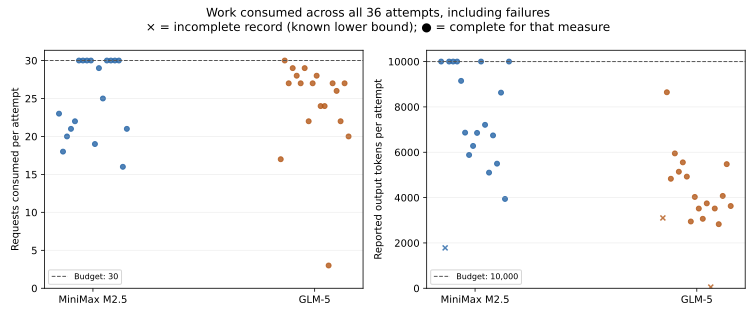

In [17]:
scope_economics, economics_audit = presentation.separate_economics(bundle)
display(HTML(presentation.transition_table_html(scope_economics)))
display(HTML(presentation.details(ROOT, "Economics by original task/configuration and run", economics_audit)))
display(presentation.distribution_table(bundle))
display(HTML("<h4>Work consumed across attempts</h4><p>Each point is one attempt’s requests or output tokens, including failed attempts. × marks incomplete records at their known lower bounds.</p>"))
asset_root, plot_receipt = presentation.assets(ROOT)
display(SVG(filename=str(asset_root / "distributions.svg")))

### One task: context and cost across requests
These charts compare both models on **the integer-temperature metadata bug, attempt 001**. The task concerns recorded metadata, not the model's sampling temperature.

- **Context:** input tokens in each request, including cached tokens. This is not a cumulative token total.
- **Cost:** cumulative reported inference charge within the attempt. Missing charges are not filled in or connected across.

The legend identifies each model. The final evaluation outcome is annotated only at the end of its attempt. This example illustrates the traces; it does not establish that context size caused success or failure.

Task,Attempt,Model,Patch accepted
Issue #35300 — Keep integer temperature values in tracing metadata.,1,MiniMax M2.5,False
Issue #35300 — Keep integer temperature values in tracing metadata.,1,GLM-5,True


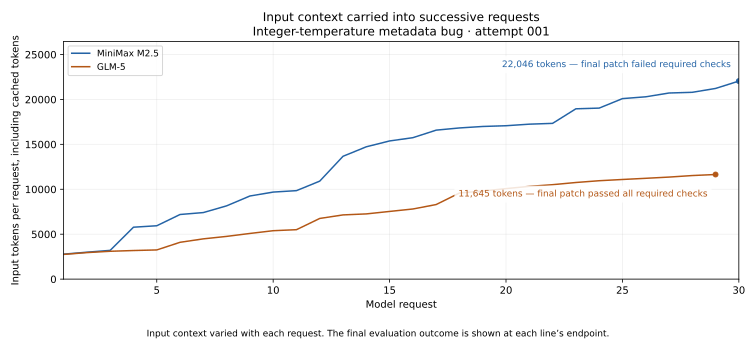

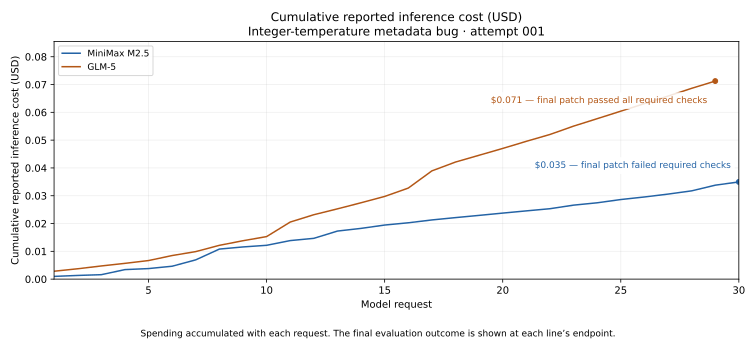

In [18]:
display(HTML(presentation.results_table_html(pd.DataFrame([{
    "Task": presentation.task_label(plot_receipt["matched_task"]), "Attempt": plot_receipt["matched_attempt"],
    "Model": presentation.MODELS[by_id[rid]["model"]], "Patch accepted": by_id[rid]["patch_accepted"]}
    for rid in plot_receipt["matched_runs"]]))))
display(HTML(presentation.details(ROOT, "Matched trajectory identities and plot provenance", plot_receipt)))
display(SVG(filename=str(asset_root / "matched-context.svg")))
display(SVG(filename=str(asset_root / "matched-cost.svg")))

### Which timing records can we use?
The medians include only attempts with a valid saved clock audit, a finite non-negative duration and no infrastructure interruption. Excluded records remain in the outcome and cost tables.

These are **agent execution times across eligible attempts**, including failures—not time per successful patch or a matched estimate of model speed.

In [19]:
timing = workflow.timing_eligibility(ROOT, held.to_dict("records"))
timing_display = timing.assign(model=timing["model"].map(presentation.MODELS))
display(timing_display.groupby(["model", "timing_status"]).size().rename("Attempts").reset_index()
    .rename(columns={"model": "Model", "timing_status": "Timing eligibility"}))
eligible = timing[timing["timing_status"] == "eligible non-interrupted"]
display(eligible.groupby("model").agg(eligible_observations=("run_id", "size"),
    median_eligible_agent_seconds=("eligible_agent_seconds", "median")).reset_index()
    .assign(model=lambda frame: frame["model"].map(presentation.MODELS))
    .rename(columns={"model": "Model", "eligible_observations": "Eligible attempts",
        "median_eligible_agent_seconds": "Median eligible agent time (seconds)"}))
display(HTML(presentation.details(ROOT, "Timing exclusions and exact saved audits", timing.to_dict("records"))))

,Model,Timing eligibility,Attempts
0,GLM-5,clock invalid,2
1,GLM-5,eligible non-interrupted,14
2,GLM-5,interrupted: excluded from medians,2
3,MiniMax M2.5,eligible non-interrupted,17
4,MiniMax M2.5,interrupted: excluded from medians,1


,Model,Eligible attempts,Median eligible agent time (seconds)
0,MiniMax M2.5,17,174.860160
1,GLM-5,14,122.159897


### Total known project spending
These non-overlapping categories include development, both held-out groups, setup and separately recorded infrastructure incidents across all archived models. Their scope is broader than the six-task comparison.

The sum is **known spending**, not a complete bill: some charges are missing.

In [20]:
spend_buckets, spending = presentation.spending_reconciliation(bundle)
display(spend_buckets)
print("Known operational spend in this saved ledger: $" + spending["known_operational_spend_usd"])
print("Complete operational spend:", spending["complete_operational_spend_usd"] or "unknown")
print("Earlier $2.60 headline:", spending["earlier_2_60_claim"])
display(HTML(presentation.details(ROOT, "Evidence version, scope and accounting provenance", spending)))
display(HTML(presentation.details(ROOT, "Separate earlier two-task block", comparison(bundle, "held_out_two").to_dict("records"))))

Known operational spend in this saved ledger: $2.76420370
Complete operational spend: unknown
Earlier $2.60 headline: No matching dated/scope receipt identified; do not use as a reconciled project total.


,Scope,Requests,Known spend USD,Unpriced request rows
0,Development tuning,365,0.57889337,2
1,Excluded infrastructure incidents,13,0.01459125,0
2,Six-task repeated evaluation (36 launches),891,1.91816912,3
3,First two held-out tasks (4 launches),106,0.25125696,1
4,Trusted setup,4,0.0012930,0


### What we learned
Across six tasks with three attempts per model, **GLM-5 produced 11 accepted patches in 18 launches; MiniMax produced 2 in 18**. Infrastructure interruptions are shown separately. GLM-5 also incurred higher known inference spending. Missing charges prevent an exact cost-per-accepted-patch comparison.

Development showed that fixing behavior and completing the required workflow are separate hurdles: tests, lint, formatting and file policy can still reject a useful implementation. Environment controls helped distinguish setup failures from agent failures.

These findings describe this task set, pinned API deployments and frozen workflow. Three attempts per task do not establish a stable model ranking. Public historical tasks may also have appeared in model training data.

#### Observed adoption lessons
Inference spend is one part of adoption cost. A coding agent also requires environment preparation, reliable evaluation, operational support and human review. This study measures inference spending and context use; its development history documents additional engineering effort, but does not assign that effort a dollar value.